# Comparação de modelos para previsão de obesidade

Notebook de estudo: treina e compara RandomForest (com e sem SMOTE), LightGBM e XGBoost sobre a base pública de triagem metabólica, nas duas variantes de feature engineering — **com** e **sem** *binning* das cinco escalas ordinais (A/B explícito, ADR 0002).

Autor: **Vinícius Ventura**.

> Os dados exibidos são fictícios e servem apenas para demonstração. Nenhum registro corresponde a uma pessoa real. Esta ferramenta é de triagem e não substitui avaliação clínica.

A proveniência do conjunto (repositório público, DOI, licença e a nota dos autores sobre a parte sintética) está em `../data/bruto/FONTE.md`. O notebook lê o CSV diretamente, de propósito: é um documento de estudo e precisa rodar numa máquina limpa, sem banco nenhum. O artefato servido pela API **não** é produzido aqui — a serialização vive em `backend/app/treino/__main__.py`, e `study/README.md` mapeia cada célula para a função do backend que a reproduz.


## Carregamento e visão geral dos dados

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import seaborn as sns
from imblearn.over_sampling import SMOTE
from lightgbm import LGBMClassifier
from sklearn.metrics import accuracy_score, classification_report, f1_score, recall_score
from xgboost import XGBClassifier

warnings.filterwarnings('ignore')

df = pd.read_csv('../data/bruto/obesity.csv')
df.head()

,Gender,Age,Height,Weight,family_history,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,Obesity
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


### Tratamento e tradução

In [2]:
df.columns

Index(['Gender', 'Age', 'Height', 'Weight', 'family_history', 'FAVC', 'FCVC',
       'NCP', 'CAEC', 'SMOKE', 'CH2O', 'SCC', 'FAF', 'TUE', 'CALC', 'MTRANS',
       'Obesity'],
      dtype='object')

In [3]:
# renomeação das colunas conforme as descrições do dicionário
colunas_map = {
    'Gender': 'Genero',
    'Age': 'Idade',
    'Height': 'Altura',
    'Weight': 'Peso',
    'family_history': 'Historico_Familiar_Sobrepeso',
    'FAVC': 'Consumo_Calorico_Frequente',
    'FCVC': 'Consumo_Vegetais',
    'NCP': 'Numero_Refeicoes_Principais',
    'CAEC': 'Consumo_Alimentos_Entre_Refeicoes',
    'SMOKE': 'Fumante',
    'CH2O': 'Consumo_Agua_Diario',
    'SCC': 'Monitoramento_Calorias',
    'FAF': 'Atividade_Fisica_Frequencia',
    'TUE': 'Tempo_Dispositivos_Tecnologicos',
    'CALC': 'Consumo_Alcool',
    'MTRANS': 'Meio_Transporte',
    'Obesity': 'Nivel_Obesidade'
}

df = df.rename(columns=colunas_map)

# arredondamento de valores decimais ("ruído") conforme instruções do dicionário
# colunas que devem ser inteiras: FCVC, NCP, CH2O, FAF, TUE
cols_para_arredondar = [
    'Consumo_Vegetais', 'Numero_Refeicoes_Principais', 
    'Consumo_Agua_Diario', 'Atividade_Fisica_Frequencia', 
    'Tempo_Dispositivos_Tecnologicos'
]

for col in cols_para_arredondar:
    if col in df.columns:
        df[col] = df[col].round().astype(int)

# dicionários de tradução dos valores internos
traducoes_valores = {
    'Genero': {'Female': 'Feminino', 'Male': 'Masculino'},
    'Historico_Familiar_Sobrepeso': {'yes': 'Sim', 'no': 'Não'},
    'Consumo_Calorico_Frequente': {'yes': 'Sim', 'no': 'Não'},
    'Fumante': {'yes': 'Sim', 'no': 'Não'},
    'Monitoramento_Calorias': {'yes': 'Sim', 'no': 'Não'},
    'Consumo_Alimentos_Entre_Refeicoes': {
        'no': 'Não', 'Sometimes': 'Às vezes', 'Frequently': 'Frequentemente', 'Always': 'Sempre'
    },
    'Consumo_Alcool': {
        'no': 'Não', 'Sometimes': 'Às vezes', 'Frequently': 'Frequentemente', 'Always': 'Sempre'
    },
    'Meio_Transporte': {
        'Automobile': 'Carro', 
        'Motorbike': 'Moto', 
        'Bike': 'Bicicleta', 
        'Public_Transportation': 'Transporte Público', 
        'Walking': 'Caminhada'
    },
    'Nivel_Obesidade': {
        'Insufficient_Weight': 'Abaixo do Peso',
        'Normal_Weight': 'Peso Normal',
        'Overweight_Level_I': 'Sobrepeso I',
        'Overweight_Level_II': 'Sobrepeso II',
        'Obesity_Type_I': 'Obesidade I',
        'Obesity_Type_II': 'Obesidade II',
        'Obesity_Type_III': 'Obesidade III'
    }
}

# aplicando as traduções
for coluna, mapeamento in traducoes_valores.items():
    if coluna in df.columns:
        df[coluna] = df[coluna].map(mapeamento)


df

,Genero,Idade,Altura,Peso,Historico_Familiar_Sobrepeso,Consumo_Calorico_Frequente,Consumo_Vegetais,Numero_Refeicoes_Principais,Consumo_Alimentos_Entre_Refeicoes,Fumante,Consumo_Agua_Diario,Monitoramento_Calorias,Atividade_Fisica_Frequencia,Tempo_Dispositivos_Tecnologicos,Consumo_Alcool,Meio_Transporte,Nivel_Obesidade
0,Feminino,21.000000,1.620000,64.000000,Sim,Não,2,3,Às vezes,Não,2,Não,0,1,Não,Transporte Público,Peso Normal
1,Feminino,21.000000,1.520000,56.000000,Sim,Não,3,3,Às vezes,Sim,3,Sim,3,0,Às vezes,Transporte Público,Peso Normal
2,Masculino,23.000000,1.800000,77.000000,Sim,Não,2,3,Às vezes,Não,2,Não,2,1,Frequentemente,Transporte Público,Peso Normal
3,Masculino,27.000000,1.800000,87.000000,Não,Não,3,3,Às vezes,Não,2,Não,2,0,Frequentemente,Caminhada,Sobrepeso I
4,Masculino,22.000000,1.780000,89.800000,Não,Não,2,1,Às vezes,Não,2,Não,0,0,Às vezes,Transporte Público,Sobrepeso II
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2106,Feminino,20.976842,1.710730,131.408528,Sim,Sim,3,3,Às vezes,Não,2,Não,2,1,Às vezes,Transporte Público,Obesidade III
2107,Feminino,21.982942,1.748584,133.742943,Sim,Sim,3,3,Às vezes,Não,2,Não,1,1,Às vezes,Transporte Público,Obesidade III
2108,Feminino,22.524036,1.752206,133.689352,Sim,Sim,3,3,Às vezes,Não,2,Não,1,1,Às vezes,Transporte Público,Obesidade III
2109,Feminino,24.361936,1.739450,133.346641,Sim,Sim,3,3,Às vezes,Não,3,Não,1,1,Às vezes,Transporte Público,Obesidade III


### Análise preliminar

In [4]:
print('Dimensões:', df.shape)
print('Valores nulos por coluna:')
print(df.isnull().sum())

Dimensões: (2111, 17)
Valores nulos por coluna:
Genero                               0
Idade                                0
Altura                               0
Peso                                 0
Historico_Familiar_Sobrepeso         0
Consumo_Calorico_Frequente           0
Consumo_Vegetais                     0
Numero_Refeicoes_Principais          0
Consumo_Alimentos_Entre_Refeicoes    0
Fumante                              0
Consumo_Agua_Diario                  0
Monitoramento_Calorias               0
Atividade_Fisica_Frequencia          0
Tempo_Dispositivos_Tecnologicos      0
Consumo_Alcool                       0
Meio_Transporte                      0
Nivel_Obesidade                      0
dtype: int64


Distribuição da variável alvo.

In [5]:
df.describe().round()

,Idade,Altura,Peso,Consumo_Vegetais,Numero_Refeicoes_Principais,Consumo_Agua_Diario,Atividade_Fisica_Frequencia,Tempo_Dispositivos_Tecnologicos
count,2111.0,2111.0,2111.0,2111.0,2111.0,2111.0,2111.0,2111.0
mean,24.0,2.0,87.0,2.0,3.0,2.0,1.0,1.0
std,6.0,0.0,26.0,1.0,1.0,1.0,1.0,1.0
min,14.0,1.0,39.0,1.0,1.0,1.0,0.0,0.0
25%,20.0,2.0,65.0,2.0,3.0,2.0,0.0,0.0
50%,23.0,2.0,83.0,2.0,3.0,2.0,1.0,1.0
75%,26.0,2.0,107.0,3.0,3.0,2.0,2.0,1.0
max,61.0,2.0,173.0,3.0,4.0,3.0,3.0,2.0


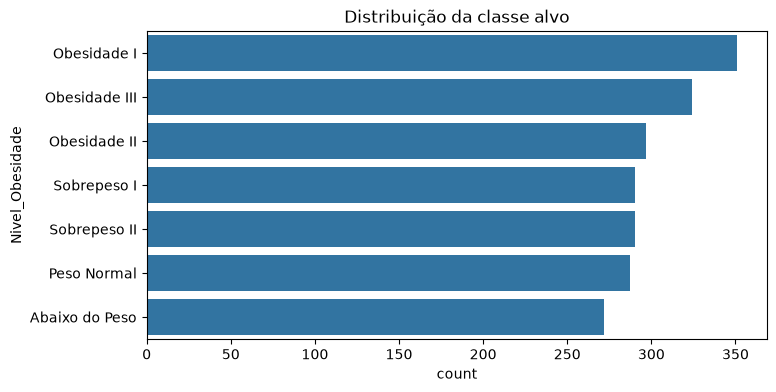

In [6]:
plt.figure(figsize=(8,4))
sns.countplot(y='Nivel_Obesidade', data=df, order=df['Nivel_Obesidade'].value_counts().index, )
plt.title('Distribuição da classe alvo')
plt.show()

In [7]:
#  gráfico por cluster - peso x altura - cluster nivel de obesidade

fig = px.scatter(
    df, 
    x="Peso", 
    y="Altura", 
    size="Idade",           # O tamanho da bolha representa a idade
    color="Nivel_Obesidade",      # A cor representa o nível de obesidade
    hover_name="Genero",  # Informação extra ao passar o mouse
    title="Análise de relação peso, altura e idade (Tamanho)",
    labels={
        "Weight": "Peso",
        "Height": "Altura",
        "Obesity": "Nível de Obesidade"
    })

# Ajustando a legenda e layout para ficar igual ao print
fig.update_layout(
    legend_title_text='Nível de Obesidade',
    title_x=0.05  # Alinha o título à esquerda
)

fig.show()

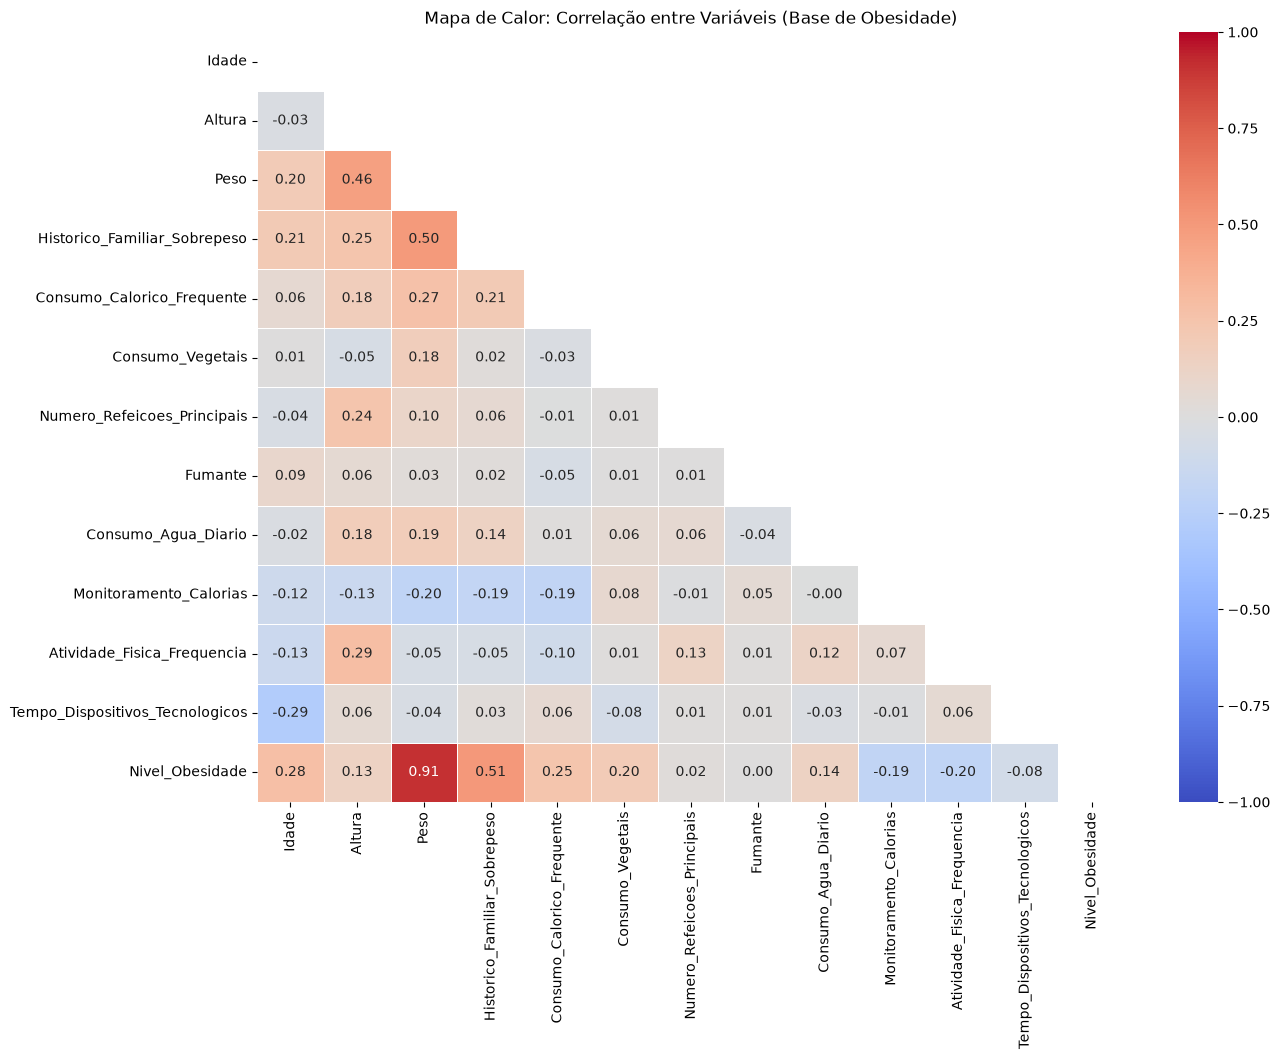

In [8]:
# heatmap
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Preparando o DF: Apenas colunas numéricas ou transformadas
# Criamos uma cópia para não afetar o original
df_corr = df.copy()

# Transformando variáveis binárias em 0 e 1 para entrarem na correlação
binarias = ['Historico_Familiar_Sobrepeso', 'Consumo_Calorico_Frequente', 'Fumante', 'Monitoramento_Calorias']
for col in binarias:
    df_corr[col] = df_corr[col].map({'Sim': 1, 'Não': 0})

# Transformando a Escala de Obesidade em Numérica (Ordinal) para correlação
obesidade_ordem = {
    'Abaixo do Peso': 0, 'Peso Normal': 1, 'Sobrepeso I': 2, 
    'Sobrepeso II': 3, 'Obesidade I': 4, 'Obesidade II': 5, 'Obesidade III': 6
}
df_corr['Nivel_Obesidade'] = df_corr['Nivel_Obesidade'].map(obesidade_ordem)

# 2. Calculando a Matriz de Correlação
corr = df_corr.select_dtypes(include=[np.number]).corr()

# 3. Gerando o Heatmap
plt.figure(figsize=(14, 10))

# Criando uma máscara para esconder a parte de cima (triângulo superior) que é repetida
mask = np.triu(np.ones_like(corr, dtype=bool))

sns.heatmap(
    corr, 
    mask=mask, 
    annot=True,          # Mostra os valores dentro dos quadrados
    fmt=".2f",           # Duas casas decimais
    cmap='coolwarm',     # Cores: azul (negativo), branco (neutro), vermelho (positivo)
    vmin=-1, vmax=1,     # Garante que a escala vá de -1 a 1
    center=0,
    linewidths=.5
)

plt.title('Mapa de Calor: Correlação entre Variáveis (Base de Obesidade)')
plt.show()

## Preparação dos dados e divisão em treino/teste

**Correção de contrato em relação ao artefato herdado:** o `OneHotEncoder` passa a usar `handle_unknown='error'` com `categories=` explícito. O default `'ignore'` do notebook original devolvia zeros em silêncio para qualquer valor fora do domínio de treino — foi exatamente isso que escondeu, em produção, as escalas ordinais enviadas como texto de faixa e as opções de transporte que não existiam no encoder (ver `docs/auditoria-do-legado.md`). Com `'error'`, categoria desconhecida vira exceção aqui e `422` na API.

A função `engineer_features` abaixo é a referência canônica do *binning* (célula 14, bloco a). Ela só entra no pipeline na variante **com binning** do A/B; a variante **sem binning** usa a identidade.

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, LabelEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer
from imblearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone
import numpy as np
import pandas as pd

# 1. Ajuste da Feature Engineering com nomes traduzidos
def engineer_features(df):
    df = df.copy()
    # Mapeamento baseado nas escalas do dicionário [cite: 9, 12, 17, 20, 21]
    bins_map = {
        'Consumo_Vegetais': ([0, 1.5, 2.5, 4], ['baixa', 'moderada', 'alta']), # FCVC
        'Numero_Refeicoes_Principais': ([0, 2.5, 3.5, 10], ['1-2', '3', '4+']), # NCP
        'Consumo_Agua_Diario': ([0, 1.5, 2.5, 10], ['<1L', '1-2L', '>2L']), # CH2O
        'Atividade_Fisica_Frequencia': ([0, 0.5, 1.5, 2.5, 10], ['nenhuma', 'baixa', 'media', 'alta']), # FAF
        'Tempo_Dispositivos_Tecnologicos': ([0, 0.5, 1.5, 10], ['0-2h', '3-5h', '>5h']), # TUE
    }
    
    for col, (bins, labels) in bins_map.items():
        if col in df.columns:
            # Garante que os dados sejam numéricos antes do cut (caso tenham sido arredondados para int)
            df[col] = pd.to_numeric(df[col], errors='coerce')
            cat = pd.cut(df[col], bins=bins, labels=labels, include_lowest=True, right=False)
            df[col] = cat.astype(str)
    return df

# 2. Definição do Alvo e Variáveis com nomes traduzidos
TARGET = 'Nivel_Obesidade'
X = df.drop(columns=[TARGET])
y = df[TARGET]

# 3. Colunas por LISTA EXPLÍCITA, não por select_dtypes (ADR 0002): as 5 escalas ordinais entram
#    no ramo categórico POR DECISÃO. Com select_dtypes e o binning desligado elas cairiam no ramo
#    numérico e o modelo teria 31 features em vez de 43.
COLUNAS_CATEGORICAS = [
    'Genero', 'Historico_Familiar_Sobrepeso', 'Consumo_Calorico_Frequente',
    'Consumo_Vegetais', 'Numero_Refeicoes_Principais',
    'Consumo_Alimentos_Entre_Refeicoes', 'Fumante', 'Consumo_Agua_Diario',
    'Monitoramento_Calorias', 'Atividade_Fisica_Frequencia',
    'Tempo_Dispositivos_Tecnologicos', 'Consumo_Alcool', 'Meio_Transporte',
]
COLUNAS_NUMERICAS = ['Idade', 'Altura', 'Peso']

# 4. Pipeline de Preprocessamento, parametrizado pela variante do A/B (com/sem binning).
#    handle_unknown='error' com categories= explícito: foi o 'ignore' que escondeu as divergências
#    do artefato legado (docs/auditoria-do-legado.md). As categorias vêm da base inteira, para a
#    largura do modelo não depender do split — Consumo_Alcool='Sempre' tem 1 ocorrência.
def montar_preprocess(binning: bool):
    base = engineer_features(X) if binning else X
    categorias = [sorted(base[c].unique()) for c in COLUNAS_CATEGORICAS]
    return ColumnTransformer([
        ('categorical', OneHotEncoder(categories=categorias, handle_unknown='error',
                                      sparse_output=False), COLUNAS_CATEGORICAS),
        ('numeric', 'passthrough', COLUNAS_NUMERICAS),
    ])

def montar_feature_engineering(binning: bool):
    # Com binning desligado o passo é a identidade nomeada — equivalente a não existir.
    return FunctionTransformer(engineer_features) if binning else FunctionTransformer()

# 5. Label Encoding do Alvo Traduzido
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# 6. Lógica de Risco Atualizada para Português
# Define classes de risco (Sobrepeso e Obesidade) conforme dicionário
RISK_CLASSES = [
    'Sobrepeso I', 'Sobrepeso II',
    'Obesidade I', 'Obesidade II', 'Obesidade III'
]

def to_risk_flag(y_encoded_vals):
    labels = label_encoder.inverse_transform(y_encoded_vals)
    return np.array([1 if lbl in RISK_CLASSES else 0 for lbl in labels])

# 7. Split dos Dados
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

# Verificação registrada no ADR 0002: a categoria rara precisa estar no treino. Se um dia falhar,
# a resposta é o categories= explícito acima — nunca mexer no split congelado.
assert set(X_train['Consumo_Alcool'].unique()) == set(df['Consumo_Alcool'].unique())

print("Classes mapeadas pelo LabelEncoder:", label_encoder.classes_)

Classes mapeadas pelo LabelEncoder: ['Abaixo do Peso' 'Obesidade I' 'Obesidade II' 'Obesidade III'
 'Peso Normal' 'Sobrepeso I' 'Sobrepeso II']


In [10]:
# Paridade notebook <-> backend (F4): a função acima e a do backend produzem o MESMO DataFrame, e
# preparar_base reproduz a célula 5. Com o venv do backend (uv sync) o pacote `app` já está
# importável; noutro ambiente, instale-o antes desta célula: pip install -e ../backend
try:
    from app.dominio.features import engineer_features as _fe_backend, preparar_base as _pb_backend
    pd.testing.assert_frame_equal(engineer_features(X.head(50)), _fe_backend(X.head(50), binning=True))
    pd.testing.assert_frame_equal(X.head(50), _fe_backend(X.head(50)))
    pd.testing.assert_frame_equal(df, _pb_backend(pd.read_csv('../data/bruto/obesity.csv')))
    print("paridade notebook <-> backend: OK")
except ImportError:
    print("backend nao instalado: rode pip install -e ../backend para checar a paridade")

paridade notebook <-> backend: OK


## Treino e avaliação dos modelos

Cada candidato é treinado **duas vezes**, uma por variante do A/B de *binning* (`_sem_binning` e `_com_binning`); o RandomForest também roda sem SMOTE, para medir o efeito da reamostragem. Os hiperparâmetros, o split e as métricas são os congelados em `study/README.md`.

In [11]:
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.pipeline import Pipeline as SkPipeline

# Lista para armazenar e comparar os resultados posteriores
results = []

def _sufixo(binning):
    return 'com_binning' if binning else 'sem_binning'

def _avaliar(rotulo, pipe, smote, binning):
    pipe.fit(X_train, y_train)
    preds = pipe.predict(X_test)

    # Métricas
    acc = accuracy_score(y_test, preds)
    f1 = f1_score(y_test, preds, average='macro')
    # to_risk_flag utiliza as classes traduzidas para identificar riscos
    recall_risk = recall_score(to_risk_flag(y_test), to_risk_flag(preds), zero_division=0)

    print(f"=== {rotulo} ({'Com' if smote else 'Sem'} SMOTE) ===")
    print(f"Acuracia: {acc:.3f} | F1-macro: {f1:.3f} | Recall risco: {recall_risk:.3f}")
    print(classification_report(y_test, preds, target_names=label_encoder.classes_))

    results.append({
        'name': rotulo,
        'pipeline': pipe,
        'accuracy': acc,
        'f1': f1,
        'recall_risk': recall_risk,
        'smote': smote,
        'binning': binning,
    })

# 1. Função SEM SMOTE (Pipeline padrão do Scikit-Learn)
#    clone(): o notebook original reutilizava o MESMO objeto estimador nos dois pipelines, e o
#    segundo fit sobrescrevia o modelo do primeiro (as duas linhas de RandomForest tinham números
#    idênticos no teste de overfitting). Cada pipeline agora treina a sua própria cópia.
def train_and_evaluate_n_smote(name, estimator, binning=False):
    pipe = SkPipeline([
        ('feature_engineering', montar_feature_engineering(binning)),
        ('columns', montar_preprocess(binning)),
        ('model', clone(estimator)),
    ])
    _avaliar(f"{name}_sem_smote_{_sufixo(binning)}", pipe, smote=False, binning=binning)

# 2. Função COM SMOTE (Pipeline do Imbalanced-Learn)
def train_and_evaluate(name, estimator, binning=False):
    # É necessário usar o Pipeline do imblearn para que o SMOTE só atue no treino
    pipe = ImbPipeline([
        ('feature_engineering', montar_feature_engineering(binning)),
        ('columns', montar_preprocess(binning)),
        ('sampler', SMOTE(sampling_strategy='auto', k_neighbors=5, random_state=42)),
        ('model', clone(estimator)),
    ])
    _avaliar(f"{name}_{_sufixo(binning)}", pipe, smote=True, binning=binning)

# Random Forest

In [12]:
rf = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1,
    class_weight='balanced_subsample',
)

for binning in (False, True):
    train_and_evaluate_n_smote('RandomForest', rf, binning=binning)
    train_and_evaluate('RandomForest', rf, binning=binning)

=== RandomForest_sem_smote_sem_binning (Sem SMOTE) ===
Acuracia: 0.922 | F1-macro: 0.921 | Recall risco: 0.958
                precision    recall  f1-score   support

Abaixo do Peso       0.98      0.94      0.96        54
   Obesidade I       0.96      0.94      0.95        70
  Obesidade II       1.00      1.00      1.00        60
 Obesidade III       1.00      1.00      1.00        65
   Peso Normal       0.75      0.84      0.80        58
   Sobrepeso I       0.87      0.83      0.85        58
  Sobrepeso II       0.89      0.88      0.89        58

      accuracy                           0.92       423
     macro avg       0.92      0.92      0.92       423
  weighted avg       0.92      0.92      0.92       423



=== RandomForest_sem_binning (Com SMOTE) ===
Acuracia: 0.924 | F1-macro: 0.923 | Recall risco: 0.952
                precision    recall  f1-score   support

Abaixo do Peso       0.96      0.94      0.95        54
   Obesidade I       1.00      0.96      0.98        70
  Obesidade II       1.00      1.00      1.00        60
 Obesidade III       1.00      1.00      1.00        65
   Peso Normal       0.74      0.86      0.79        58
   Sobrepeso I       0.85      0.81      0.83        58
  Sobrepeso II       0.93      0.88      0.90        58

      accuracy                           0.92       423
     macro avg       0.93      0.92      0.92       423
  weighted avg       0.93      0.92      0.93       423



=== RandomForest_sem_smote_com_binning (Sem SMOTE) ===
Acuracia: 0.929 | F1-macro: 0.928 | Recall risco: 0.958
                precision    recall  f1-score   support

Abaixo do Peso       0.98      0.96      0.97        54
   Obesidade I       0.99      0.94      0.96        70
  Obesidade II       1.00      1.00      1.00        60
 Obesidade III       1.00      1.00      1.00        65
   Peso Normal       0.77      0.88      0.82        58
   Sobrepeso I       0.87      0.83      0.85        58
  Sobrepeso II       0.89      0.88      0.89        58

      accuracy                           0.93       423
     macro avg       0.93      0.93      0.93       423
  weighted avg       0.93      0.93      0.93       423



=== RandomForest_com_binning (Com SMOTE) ===
Acuracia: 0.924 | F1-macro: 0.923 | Recall risco: 0.958
                precision    recall  f1-score   support

Abaixo do Peso       0.96      0.94      0.95        54
   Obesidade I       0.97      0.94      0.96        70
  Obesidade II       1.00      1.00      1.00        60
 Obesidade III       1.00      1.00      1.00        65
   Peso Normal       0.76      0.86      0.81        58
   Sobrepeso I       0.89      0.83      0.86        58
  Sobrepeso II       0.89      0.88      0.89        58

      accuracy                           0.92       423
     macro avg       0.92      0.92      0.92       423
  weighted avg       0.93      0.92      0.93       423



Com SMOTE, o recall das classes de risco do RandomForest sobe em relação ao mesmo modelo sem reamostragem; o custo é pequeno em acurácia global. Os valores exatos estão na tabela de avaliação mais abaixo — e, para o modelo servido, no `artifacts/manifest.json`, nunca nesta prosa.

# LightGBM

In [13]:
lgbm = LGBMClassifier(
    n_estimators=39,
    learning_rate=0.05,
    max_depth=-1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='multiclass',
    num_class=len(label_encoder.classes_),
    random_state=42,
    n_jobs=4,
    verbose=-1,
)

for binning in (False, True):
    train_and_evaluate('LightGBM', lgbm, binning=binning)

=== LightGBM_sem_binning (Com SMOTE) ===
Acuracia: 0.955 | F1-macro: 0.954 | Recall risco: 0.990
                precision    recall  f1-score   support

Abaixo do Peso       0.98      0.93      0.95        54
   Obesidade I       0.97      0.96      0.96        70
  Obesidade II       1.00      1.00      1.00        60
 Obesidade III       1.00      1.00      1.00        65
   Peso Normal       0.88      0.91      0.90        58
   Sobrepeso I       0.89      0.93      0.91        58
  Sobrepeso II       0.96      0.95      0.96        58

      accuracy                           0.96       423
     macro avg       0.95      0.95      0.95       423
  weighted avg       0.96      0.96      0.96       423



=== LightGBM_com_binning (Com SMOTE) ===
Acuracia: 0.950 | F1-macro: 0.949 | Recall risco: 0.987


                precision    recall  f1-score   support

Abaixo do Peso       0.96      0.93      0.94        54
   Obesidade I       0.99      0.96      0.97        70
  Obesidade II       1.00      1.00      1.00        60
 Obesidade III       1.00      1.00      1.00        65
   Peso Normal       0.87      0.90      0.88        58
   Sobrepeso I       0.88      0.90      0.89        58
  Sobrepeso II       0.95      0.97      0.96        58

      accuracy                           0.95       423
     macro avg       0.95      0.95      0.95       423
  weighted avg       0.95      0.95      0.95       423



# XGBoost

In [14]:
xgb = XGBClassifier(
    n_estimators=400,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='multi:softprob',
    eval_metric='mlogloss',
    random_state=42,
    num_class=len(label_encoder.classes_),
    n_jobs=4,
)

for binning in (False, True):
    train_and_evaluate('XGBoost', xgb, binning=binning)

=== XGBoost_sem_binning (Com SMOTE) ===
Acuracia: 0.965 | F1-macro: 0.964 | Recall risco: 0.994
                precision    recall  f1-score   support

Abaixo do Peso       0.98      0.94      0.96        54
   Obesidade I       0.99      0.97      0.98        70
  Obesidade II       0.98      1.00      0.99        60
 Obesidade III       1.00      0.98      0.99        65
   Peso Normal       0.92      0.93      0.92        58
   Sobrepeso I       0.93      0.93      0.93        58
  Sobrepeso II       0.95      0.98      0.97        58

      accuracy                           0.96       423
     macro avg       0.96      0.96      0.96       423
  weighted avg       0.96      0.96      0.96       423



=== XGBoost_com_binning (Com SMOTE) ===
Acuracia: 0.965 | F1-macro: 0.963 | Recall risco: 0.997
                precision    recall  f1-score   support

Abaixo do Peso       0.96      0.94      0.95        54
   Obesidade I       0.99      0.97      0.98        70
  Obesidade II       0.98      1.00      0.99        60
 Obesidade III       1.00      0.98      0.99        65
   Peso Normal       0.93      0.91      0.92        58
   Sobrepeso I       0.93      0.95      0.94        58
  Sobrepeso II       0.95      0.98      0.97        58

      accuracy                           0.96       423
     macro avg       0.96      0.96      0.96       423
  weighted avg       0.96      0.96      0.96       423



# Avaliação dos modelos

In [15]:
summary = pd.DataFrame([
    {
        'Modelo': r['name'],
        'SMOTE': r['smote'],
        'Binning': r['binning'],
        'Acuracia %': round(r['accuracy']*100,2),
        'F1-macro %': round(r['f1']*100,2),
        'Recall risco %': round(r['recall_risk']*100,2),
    } for r in results
]).sort_values(by=['Recall risco %', 'Acuracia %'], ascending=False).reset_index(drop=True)
summary

,Modelo,SMOTE,Binning,Acuracia %,F1-macro %,Recall risco %
0,XGBoost_com_binning,True,True,96.45,96.34,99.68
1,XGBoost_sem_binning,True,False,96.45,96.36,99.36
2,LightGBM_sem_binning,True,False,95.51,95.41,99.04
3,LightGBM_com_binning,True,True,95.04,94.88,98.71
4,RandomForest_sem_smote_com_binning,False,True,92.91,92.78,95.82
5,RandomForest_com_binning,True,True,92.43,92.29,95.82
6,RandomForest_sem_smote_sem_binning,False,False,92.20,92.07,95.82
7,RandomForest_sem_binning,True,False,92.43,92.28,95.18


# Teste de overfitting

In [16]:
def check_overfitting(name, pipeline):
    # Predições para treino e teste
    train_preds = pipeline.predict(X_train)
    test_preds = pipeline.predict(X_test)
    
    # Cálculo das métricas
    acc_train = accuracy_score(y_train, train_preds)
    acc_test = accuracy_score(y_test, test_preds)
    
    f1_train = f1_score(y_train, train_preds, average='macro')
    f1_test = f1_score(y_test, test_preds, average='macro')
    
    print(f"--- Teste de Overfitting: {name} ---")
    print(f"Acurácia - Treino: {acc_train:.3f} | Teste: {acc_test:.3f} | Diff: {acc_train - acc_test:.3f}")
    print(f"F1-Macro - Treino: {f1_train:.3f} | Teste: {f1_test:.3f} | Diff: {f1_train - f1_test:.3f}")
    
    if (acc_train - acc_test) > 0.10:
        print("ALERTA: Possível Overfitting detectado! (Diferença maior que 10%)")
    else:
        print("O modelo parece estar generalizando bem.")

In [17]:
# Percorre cada item dentro da lista de resultados
for item in results:
    # Extrai o nome e o pipeline salvos
    nome_modelo = item['name']
    pipeline_modelo = item['pipeline']
    
    # Chama a função de teste de overfitting para cada um
    check_overfitting(nome_modelo, pipeline_modelo)
    print("-" * 30) # Linha separadora para facilitar a leitura

--- Teste de Overfitting: RandomForest_sem_smote_sem_binning ---
Acurácia - Treino: 1.000 | Teste: 0.922 | Diff: 0.078
F1-Macro - Treino: 1.000 | Teste: 0.921 | Diff: 0.079
O modelo parece estar generalizando bem.
------------------------------


--- Teste de Overfitting: RandomForest_sem_binning ---
Acurácia - Treino: 1.000 | Teste: 0.924 | Diff: 0.076
F1-Macro - Treino: 1.000 | Teste: 0.923 | Diff: 0.077
O modelo parece estar generalizando bem.
------------------------------


--- Teste de Overfitting: RandomForest_sem_smote_com_binning ---
Acurácia - Treino: 1.000 | Teste: 0.929 | Diff: 0.071
F1-Macro - Treino: 1.000 | Teste: 0.928 | Diff: 0.072
O modelo parece estar generalizando bem.
------------------------------


--- Teste de Overfitting: RandomForest_com_binning ---
Acurácia - Treino: 1.000 | Teste: 0.924 | Diff: 0.076
F1-Macro - Treino: 1.000 | Teste: 0.923 | Diff: 0.077
O modelo parece estar generalizando bem.
------------------------------
--- Teste de Overfitting: LightGBM_sem_binning ---
Acurácia - Treino: 0.997 | Teste: 0.955 | Diff: 0.042
F1-Macro - Treino: 0.997 | Teste: 0.954 | Diff: 0.043
O modelo parece estar generalizando bem.
------------------------------
--- Teste de Overfitting: LightGBM_com_binning ---
Acurácia - Treino: 0.997 | Teste: 0.950 | Diff: 0.047
F1-Macro - Treino: 0.997 | Teste: 0.949 | Diff: 0.048
O modelo parece estar generalizando bem.
------------------------------


--- Teste de Overfitting: XGBoost_sem_binning ---
Acurácia - Treino: 1.000 | Teste: 0.965 | Diff: 0.035
F1-Macro - Treino: 1.000 | Teste: 0.964 | Diff: 0.036
O modelo parece estar generalizando bem.
------------------------------
--- Teste de Overfitting: XGBoost_com_binning ---
Acurácia - Treino: 1.000 | Teste: 0.965 | Diff: 0.035
F1-Macro - Treino: 1.000 | Teste: 0.963 | Diff: 0.037
O modelo parece estar generalizando bem.
------------------------------


### A/B: IMC como feature (ADR 0003)

IMC = Peso / Altura² é função determinística de duas features que já entram no modelo. Para um modelo de árvores isso não acrescenta informação, só colinearidade — mas a decisão é tomada com número na mão: o XGBoost com SMOTE, sem *binning*, treinado com e sem a coluna `IMC` sobre o **mesmo** split. Critério: recall das classes de risco; empate resolvido pelo menor gap treino/teste.

In [18]:
X_imc = X.assign(IMC=X['Peso'] / X['Altura'] ** 2)
# O split preserva o índice original: os mesmos índices valem para a variante com IMC.
X_train_imc, X_test_imc = X_imc.loc[X_train.index], X_imc.loc[X_test.index]

def _preprocess_com_imc():
    categorias = [sorted(X[c].unique()) for c in COLUNAS_CATEGORICAS]
    return ColumnTransformer([
        ('categorical', OneHotEncoder(categories=categorias, handle_unknown='error',
                                      sparse_output=False), COLUNAS_CATEGORICAS),
        ('numeric', 'passthrough', COLUNAS_NUMERICAS + ['IMC']),
    ])

ab_imc = []
for variante, prep, Xtr, Xte in (
    ('sem_imc', montar_preprocess(False), X_train, X_test),
    ('com_imc', _preprocess_com_imc(), X_train_imc, X_test_imc),
):
    pipe = ImbPipeline([
        ('columns', prep),
        ('sampler', SMOTE(sampling_strategy='auto', k_neighbors=5, random_state=42)),
        ('model', clone(xgb)),
    ])
    pipe.fit(Xtr, y_train)
    preds, preds_treino = pipe.predict(Xte), pipe.predict(Xtr)
    ab_imc.append({
        'Variante': variante,
        'Acuracia %': round(accuracy_score(y_test, preds) * 100, 2),
        'F1-macro %': round(f1_score(y_test, preds, average='macro') * 100, 2),
        'Recall risco %': round(recall_score(to_risk_flag(y_test), to_risk_flag(preds), zero_division=0) * 100, 2),
        'Gap acc treino-teste (pp)': round((accuracy_score(y_train, preds_treino) - accuracy_score(y_test, preds)) * 100, 2),
    })
pd.DataFrame(ab_imc)

,Variante,Acuracia %,F1-macro %,Recall risco %,Gap acc treino-teste (pp)
0,sem_imc,96.45,96.36,99.36,3.55
1,com_imc,98.82,98.76,99.36,1.18


### Leitura da comparação

O critério do projeto é, nesta ordem: recall das classes de risco, acurácia global e menor diferença treino/teste. O candidato que vence por esse critério é o que o CLI de treino (`python -m app.treino treinar`) persiste — na variante de *binning* decidida no ADR 0002 — e as métricas publicadas vêm de `artifacts/manifest.json`, via `GET /api/v1/model/info`. Esta prosa não é regenerada pelo *Run All*; por isso ela não carrega número nenhum.

## Persistência do artefato

A serialização do artefato vive em `backend/app/treino/__main__.py` (joblib, sem `dill`). O notebook compara modelos; ele não produz o artefato servido. Nenhum `.pkl` é escrito aqui.

# Base de estudo do painel

In [19]:
# IMC é métrica de tela, não feature do modelo (ADR 0003). As 5 escalas ficam como inteiros crus:
# o rótulo de exibição ("<1L", "nenhuma", ...) é responsabilidade da apresentação, não do dado.
df_painel = df.copy()
df_painel['IMC'] = df_painel['Peso'] / (df_painel['Altura'] ** 2)
df_painel

,Genero,Idade,Altura,Peso,Historico_Familiar_Sobrepeso,Consumo_Calorico_Frequente,Consumo_Vegetais,Numero_Refeicoes_Principais,Consumo_Alimentos_Entre_Refeicoes,Fumante,Consumo_Agua_Diario,Monitoramento_Calorias,Atividade_Fisica_Frequencia,Tempo_Dispositivos_Tecnologicos,Consumo_Alcool,Meio_Transporte,Nivel_Obesidade,IMC
0,Feminino,21.000000,1.620000,64.000000,Sim,Não,2,3,Às vezes,Não,2,Não,0,1,Não,Transporte Público,Peso Normal,24.386526
1,Feminino,21.000000,1.520000,56.000000,Sim,Não,3,3,Às vezes,Sim,3,Sim,3,0,Às vezes,Transporte Público,Peso Normal,24.238227
2,Masculino,23.000000,1.800000,77.000000,Sim,Não,2,3,Às vezes,Não,2,Não,2,1,Frequentemente,Transporte Público,Peso Normal,23.765432
3,Masculino,27.000000,1.800000,87.000000,Não,Não,3,3,Às vezes,Não,2,Não,2,0,Frequentemente,Caminhada,Sobrepeso I,26.851852
4,Masculino,22.000000,1.780000,89.800000,Não,Não,2,1,Às vezes,Não,2,Não,0,0,Às vezes,Transporte Público,Sobrepeso II,28.342381
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2106,Feminino,20.976842,1.710730,131.408528,Sim,Sim,3,3,Às vezes,Não,2,Não,2,1,Às vezes,Transporte Público,Obesidade III,44.901475
2107,Feminino,21.982942,1.748584,133.742943,Sim,Sim,3,3,Às vezes,Não,2,Não,1,1,Às vezes,Transporte Público,Obesidade III,43.741923
2108,Feminino,22.524036,1.752206,133.689352,Sim,Sim,3,3,Às vezes,Não,2,Não,1,1,Às vezes,Transporte Público,Obesidade III,43.543817
2109,Feminino,24.361936,1.739450,133.346641,Sim,Sim,3,3,Às vezes,Não,3,Não,1,1,Às vezes,Transporte Público,Obesidade III,44.071535


In [20]:
# `base_painel.parquet` é saída EXCLUSIVA de treino/agregar.py (derivada do snapshot congelado);
# o notebook grava um arquivo de estudo, com outro nome, para o Run All nunca sobrescrever o
# parquet servido. _estudo_*.parquet está no .gitignore.
Path('../data/processado').mkdir(parents=True, exist_ok=True)
df_painel.to_parquet('../data/processado/_estudo_base_painel.parquet', index=False)